# CCI-A1SD — full trustworthy-AI walkthrough

O-RAN **A1 interface** traffic (Non-RT RIC → Near-RT RIC) under three conditions: `Normal`, volumetric `DoS` and an FGN-modulated `Covert` channel. We use only the **10 defender-observable features**.

Unlike the overview notebook, here we call each pillar's functions *directly* so the API is explicit.

In [1]:
# --- bootstrap: make the `trustoran` engineering package importable ---------
import sys, pathlib
REPO = pathlib.Path.cwd().resolve()
while not (REPO / "py" / "trustoran").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "py"))

%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from trustoran import config as C
from trustoran.data import build_dataset, train_test_split_dataset
from trustoran.data.loaders import available_datasets
from trustoran.models import make_model
from trustoran.pipeline.engine import TrustPipeline, PILLARS, DATASET_PROFILES
from trustoran.viz import plotting as VZ
from trustoran.trust import explainability as EX, robustness as RB, fairness as FA, privacy as PR

print("repo root :", REPO)
print("datasets  :", available_datasets())
print("pillars   :", PILLARS)

repo root : E:\可信AI
datasets  : ['cci_a1sd', 'cci_a1sd_binary', 'ddos_pcap', 'vran_energy', 'vran_application', 'vran_computing']
pillars   : ('explainability', 'robustness', 'fairness', 'privacy')


## Load · split · train

{'name': 'cci_a1sd', 'task': 'classification', 'n_samples': 60000, 'n_features': 10, 'feature_names': ['real_interval', 'inter_arrival_mean', 'inter_arrival_std', 'inter_arrival_cv', 'response_time_mean', 'response_time_std', 'request_rate', 'payload_size_mean', 'payload_size_std', 'body_size'], 'class_names': ['Normal', 'Dos', 'Covert'], 'class_counts': {'Normal': 20000, 'Dos': 20000, 'Covert': 20000}, 'group_attrs': ['policy_type_id', 'load_label', 'operation', 'policy_name'], 'meta': {'source': 'CCI-A1SD', 'dos_variant': 'dos2', 'classes': ['normal', 'dos', 'covert'], 'per_class_cap': 20000, 'policy_names': {20008: 'Traffic Steering', 20009: 'QoS Management', 20010: 'Resource Allocation', 20011: 'Slice SLA', 20012: 'Energy Saving', 20013: 'Load Balancing', 20014: 'Cell Barring', 20015: 'Handover Steering'}}}


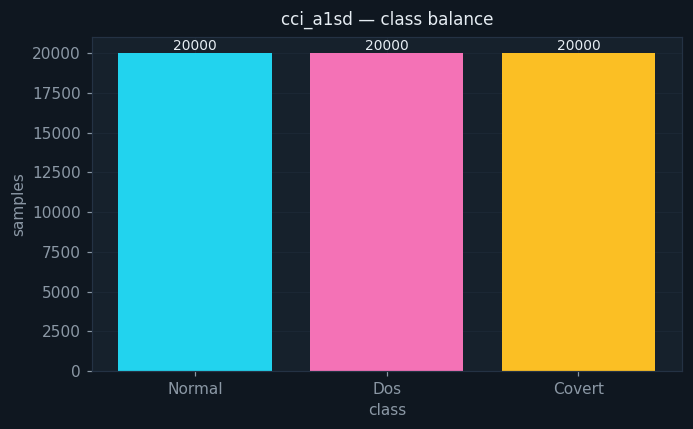

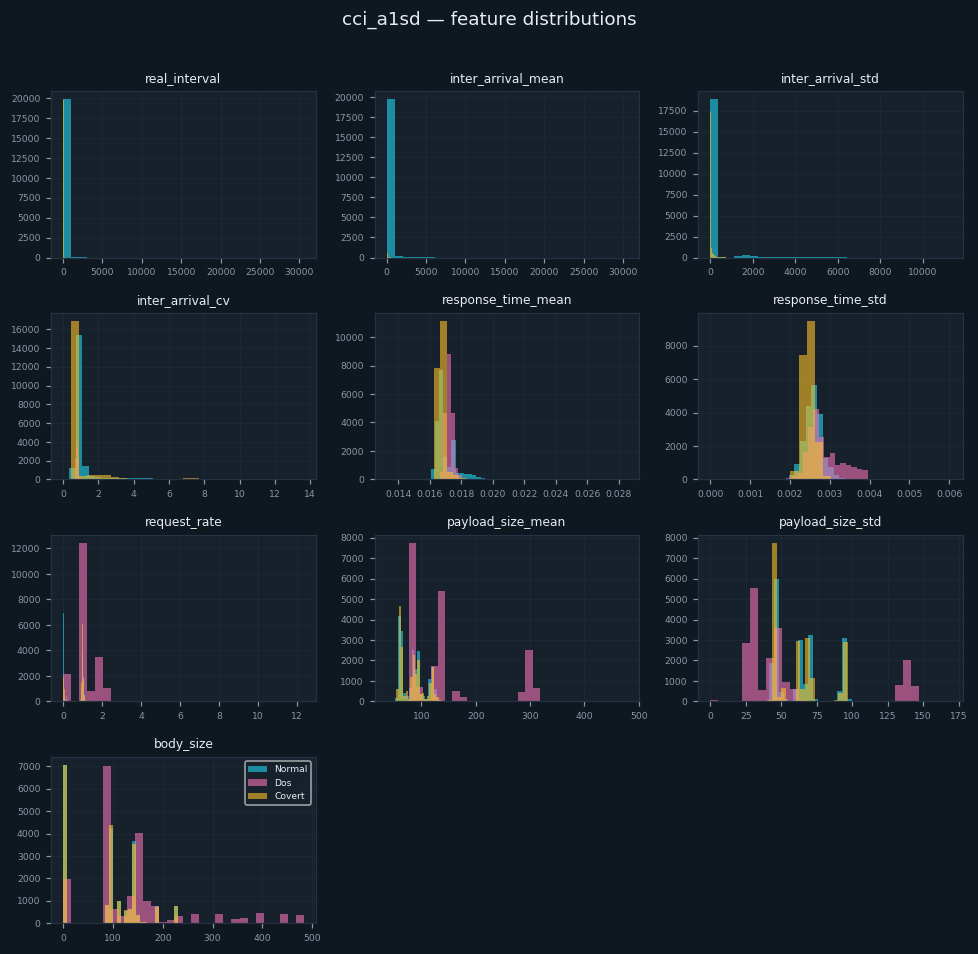

In [2]:
ds = build_dataset("cci_a1sd", max_rows=30000, seed=42)
print(ds.describe())
display(VZ.fig_class_distribution(ds))
display(VZ.fig_feature_histograms(ds, max_features=10))

In [3]:
split = train_test_split_dataset(ds, test_size=0.3, seed=42, scale=True)
model = make_model("random_forest", split.train.task, split.feature_names,
                   split.train.class_names, params={"n_estimators": 200})
model.fit(split.X_train, split.y_train)
metrics = model.score(split.X_test, split.y_test)
print("base metrics:", {k: round(v, 4) for k, v in metrics.items()})

base metrics: {'accuracy': 0.9978, 'f1_macro': 0.9978}


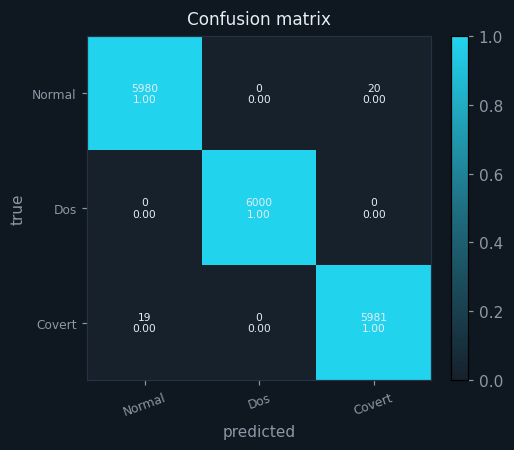

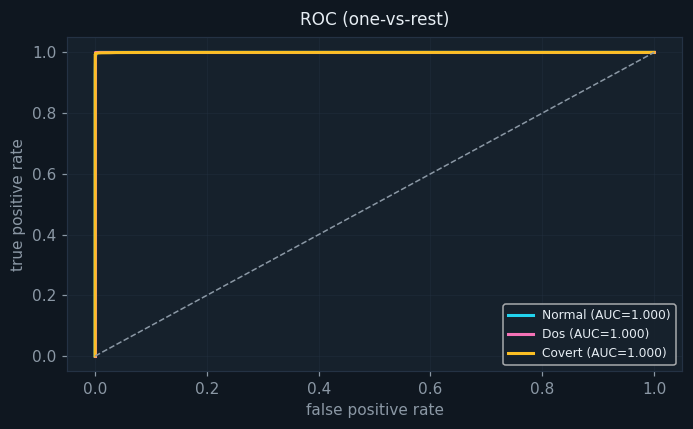

In [4]:
y_pred = model.predict(split.X_test)
display(VZ.fig_confusion_matrix(split.y_test, y_pred, ds.class_names))
display(VZ.fig_roc_curves(split.y_test, model.predict_proba(split.X_test), ds.class_names))

## Pillar 1 · Explainability

*Why* does the detector fire? Global permutation importance → KernelSHAP-style attributions → a LIME-style local surrogate → PDP/ICE.

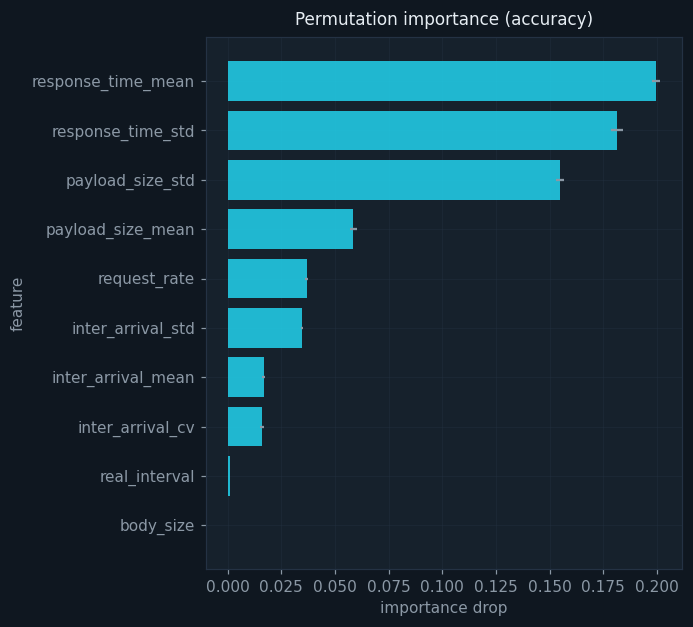

,feature,permutation,permutation_std,native
0,response_time_mean,0.199597,0.001989,0.194483
1,response_time_std,0.181507,0.002832,0.122847
2,payload_size_std,0.154785,0.001820,0.170688
3,payload_size_mean,0.058528,0.001592,0.153349
4,request_rate,0.036840,0.000727,0.086324
5,inter_arrival_std,0.034569,0.000594,0.100121


In [5]:
gi = EX.global_importance(model, split.X_test, split.y_test, n_repeats=8, seed=42)
display(VZ.fig_permutation_importance(gi))
gi.to_frame().head(6)

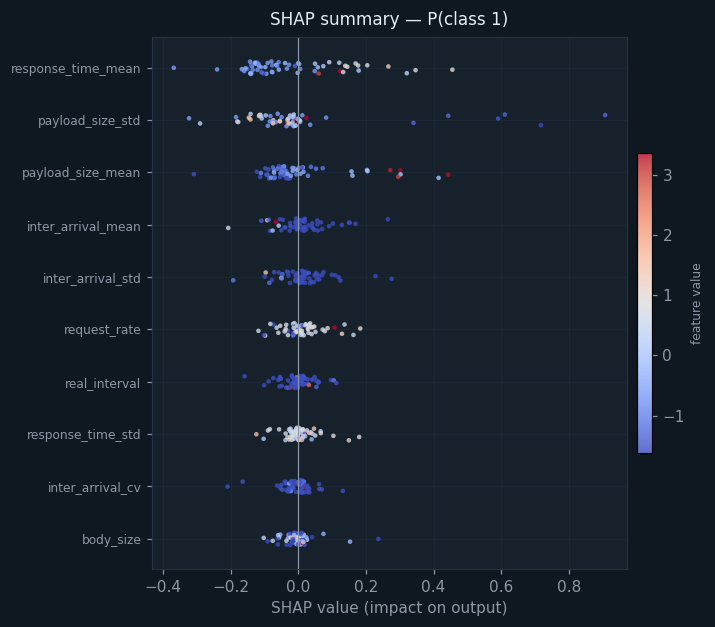

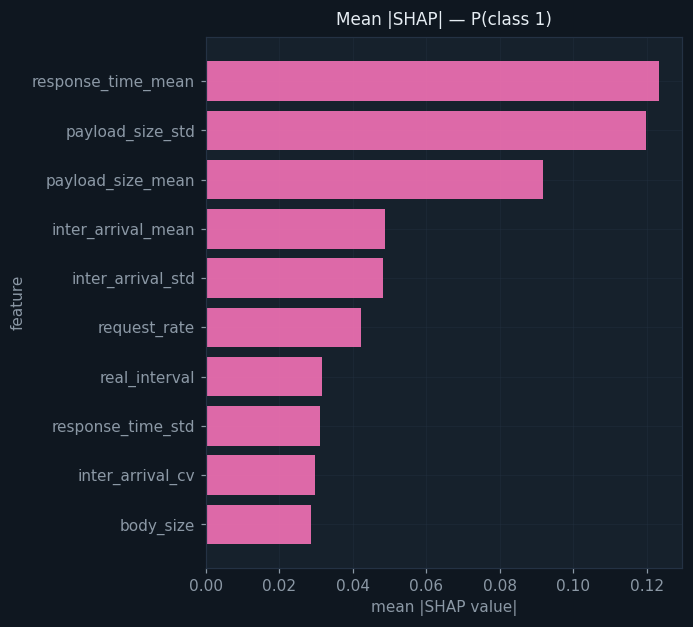

In [6]:
rng = np.random.default_rng(42)
bg = split.X_train[rng.choice(len(split.X_train), 120, replace=False)]
ex = split.X_test[rng.choice(len(split.X_test), 60, replace=False)]
sh = EX.shap_explain(model, ex, bg, target_class=1, seed=42)   # class 1 = DoS
display(VZ.fig_shap_summary(sh))
display(VZ.fig_shap_bar(sh))

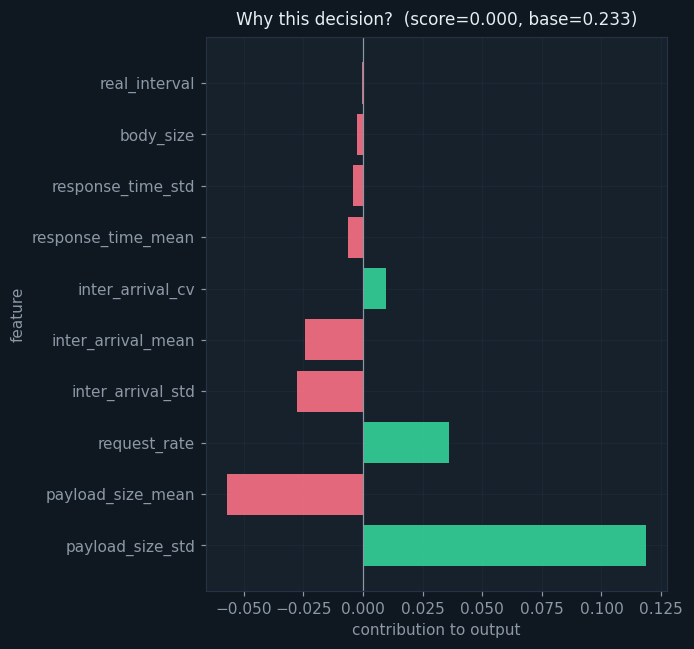

,feature,contribution
0,payload_size_std,0.118636
1,payload_size_mean,-0.057003
2,request_rate,0.036259
3,inter_arrival_std,-0.027778
4,inter_arrival_mean,-0.024228
5,inter_arrival_cv,0.009708
6,response_time_mean,-0.006080
7,response_time_std,-0.003944
8,body_size,-0.002285
9,real_interval,-0.000217


In [7]:
le = EX.local_explanation(model, ex[0], bg, target_class=1, seed=42)
display(VZ.fig_local_explanation(le))
le.to_frame()

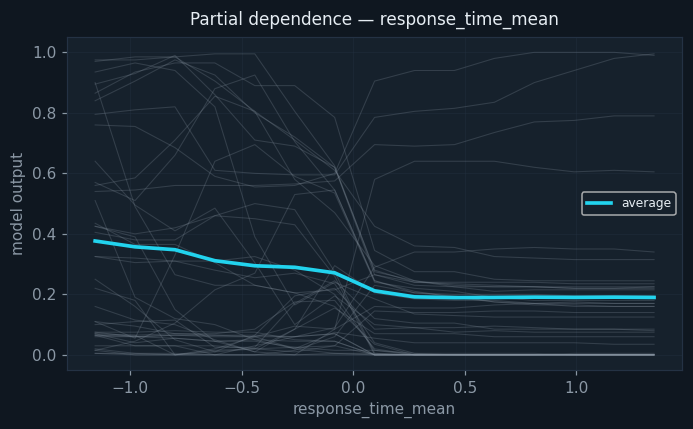

In [8]:
top_feat = gi.to_frame()["feature"].iloc[0]
fi = model.feature_names.index(top_feat)
pdp = EX.partial_dependence(model, split.X_test[:400], fi, grid_resolution=15)
display(VZ.fig_pdp(pdp))

## Pillar 2 · Robustness

Gradient-based evasion: FGSM, PGD, DeepFool, then the robustness curve and adversarial training as the defence.

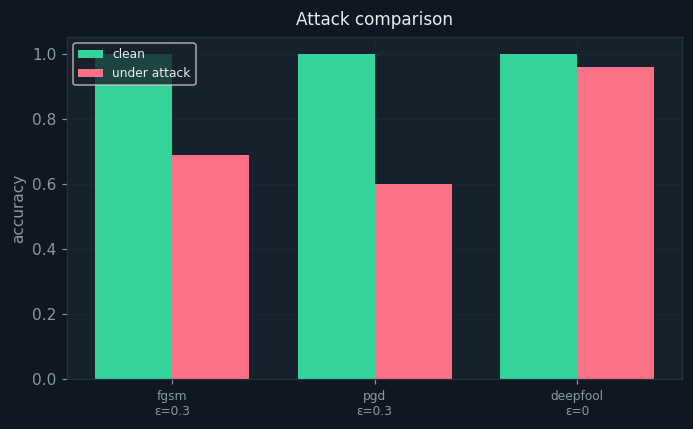

,attack,clean,robust,attack_success
0,fgsm,1.0,0.688,0.312
1,pgd,1.0,0.600,0.400
2,deepfool,1.0,0.958,0.042


In [9]:
Xs, ys = split.X_test[:400], split.y_test[:400]
attacks = [
    RB.evaluate_attack(model, Xs, ys, "fgsm", 0.3, ds.class_names),
    RB.evaluate_attack(model, Xs, ys, "pgd", 0.3, ds.class_names, seed=42),
    RB.evaluate_attack(model, Xs[:120], ys[:120], "deepfool", 0.0, ds.class_names),
]
display(VZ.fig_attack_comparison(attacks))
pd.DataFrame([{ "attack": a.attack, "clean": round(a.clean_accuracy,3),
               "robust": round(a.robust_accuracy,3),
               "attack_success": round(a.attack_success_rate,3)} for a in attacks])

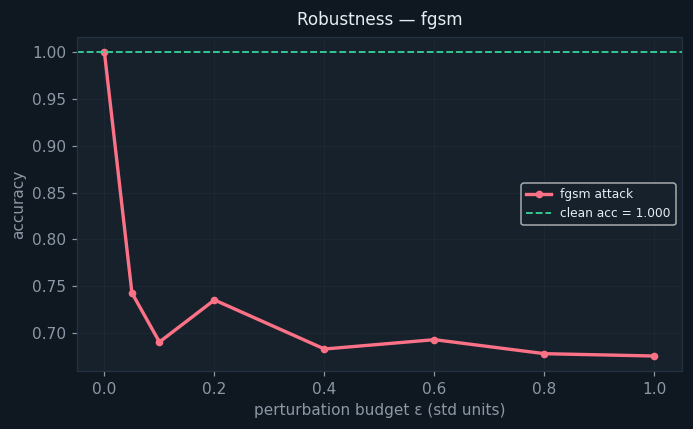

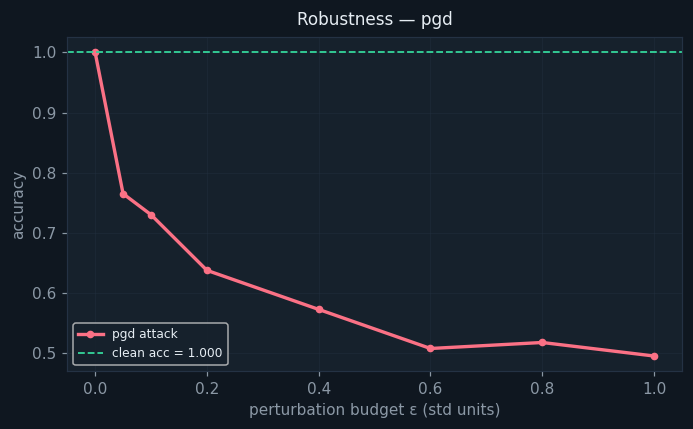

In [10]:
eps_range = (0.0, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0)
rc_fgsm = RB.robustness_curve(model, Xs, ys, "fgsm", eps_range=eps_range)
rc_pgd  = RB.robustness_curve(model, Xs, ys, "pgd",  eps_range=eps_range, seed=42)
display(VZ.fig_robustness_curve(rc_fgsm))
display(VZ.fig_robustness_curve(rc_pgd))

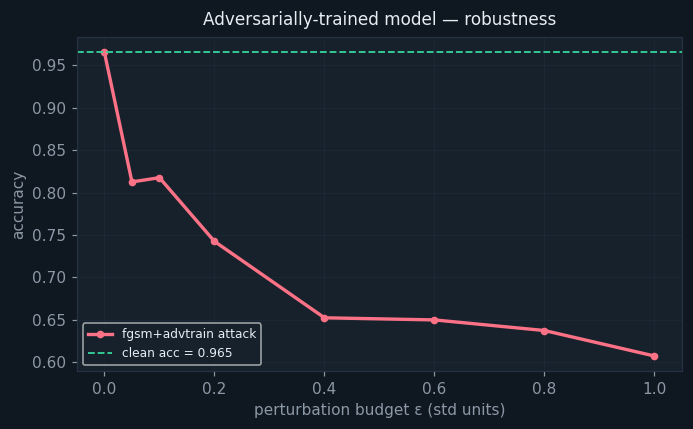

In [11]:
rc_at = RB.adversarial_training(model, split.X_train[:3000], split.y_train[:3000],
                                Xs, ys, eps=0.3, eval_eps_range=eps_range, seed=42)
display(VZ.fig_robustness_curve(rc_at, title="Adversarially-trained model — robustness"))

## Pillar 3 · Fairness

Is detection even across the **8 A1 policy types** (Traffic Steering, QoS, Energy Saving, …)? Uneven recall there means some slices are left less protected.

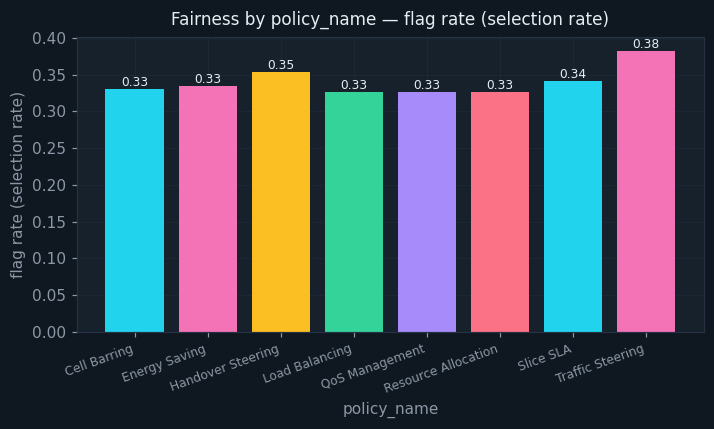

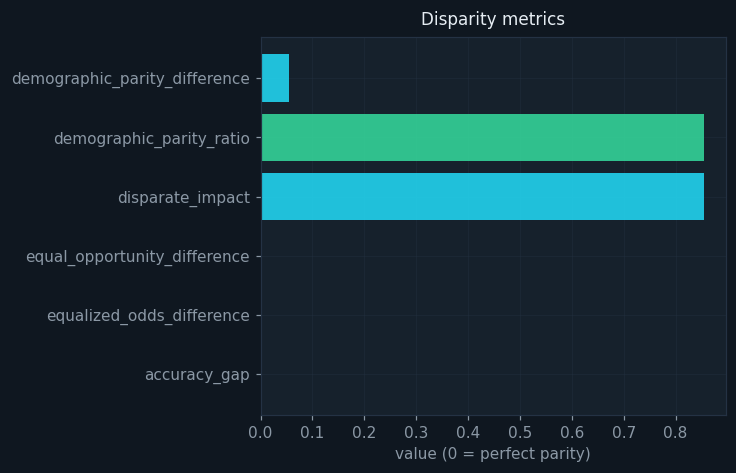

,group,n,selection_rate,tpr,fpr,fnr,accuracy,precision,positives
0,Cell Barring,623,0.330658,1.0,0.0,0.0,1.0,1.0,206
1,Energy Saving,3198,0.334271,1.0,0.0,0.0,1.0,1.0,1069
2,Handover Steering,599,0.353923,1.0,0.0,0.0,1.0,1.0,212
3,Load Balancing,3237,0.326228,1.0,0.0,0.0,1.0,1.0,1056
4,QoS Management,3278,0.326419,1.0,0.0,0.0,1.0,1.0,1070
5,Resource Allocation,3235,0.326739,1.0,0.0,0.0,1.0,1.0,1057
6,Slice SLA,3259,0.341209,1.0,0.0,0.0,1.0,1.0,1112
7,Traffic Steering,571,0.381786,1.0,0.0,0.0,1.0,1.0,218


In [12]:
groups = split.test.group_values("policy_name")
fr = FA.analyze_fairness(model, split.X_test, split.y_test, groups, "policy_name",
                         task=split.train.task, positive_class=1, class_names=ds.class_names)
display(VZ.fig_fairness_groups(fr))
display(VZ.fig_fairness_metrics(fr))
fr.group_table

## Pillar 4 · Privacy

DP-SGD privacy–utility trade-off and a membership-inference attack group (confidence threshold, label-aware meta-model, shadow-model SSA and LiRA) on the released detector.

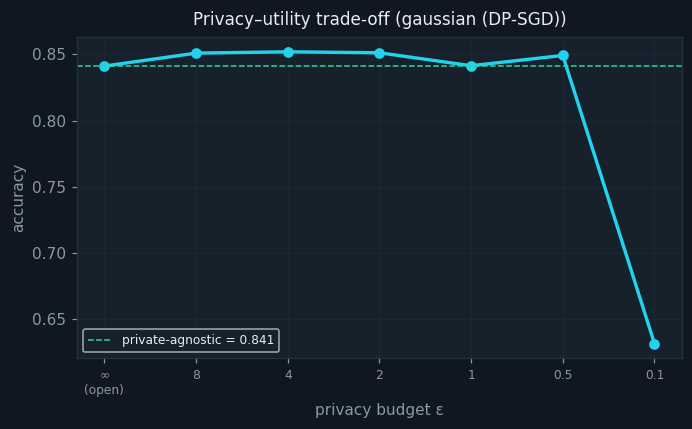

In [13]:
dp = PR.privacy_utility_curve(split.X_train[:4000], split.y_train[:4000],
                              split.X_test[:4000], split.y_test[:4000], split.train.task,
                              eps_range=(float("inf"), 8.0, 4.0, 2.0, 1.0, 0.5, 0.1),
                              epochs=25, hidden=32, seed=42)
display(VZ.fig_dp_curve(dp))

In [ ]:
mi = PR.membership_inference(model, split.X_train[:3000], split.y_train[:3000],
                             split.X_test[:3000], split.y_test[:3000], seed=42,
                             n_shadows=8)
display(VZ.fig_membership_inference(mi))
print("membership-inference AUC per attack (0.5 = no leakage):")
for k, v in mi.attack_aucs.items():
    print(f"  {k:<14} {v:.4f}")
print("  headline attack_auc: {:.4f}".format(mi.attack_auc))
print("  KS(nll)={:.4f} TPR@1%FPR={:.3f} conf_gap={:.4f} gen_gap={:.4f} "
      "near_dup={:.4f} shadows={}".format(
          mi.ks_stat, mi.tpr_at_1pct_fpr, mi.confidence_gap,
          mi.generalization_gap, mi.near_duplicate_rate, mi.n_shadows))